# 11. Rolling-Origin Backtest

Strategy 7.5 / TODO `feat/rolling-backtest`. The official split tests only
Jul-Sep 2011, the lowest-churn quarter. Its two 90-day embargoes also leave
Dec 2010 - Jan 2011 (churn 59-63%) unused. Here the same recipe (Logistic
Regression, Extended features, C=0.01, rows weighted 1/n per customer) is
refit on an **expanding window** for four test blocks, with a **90-day embargo**
between the last training snapshot and the first test snapshot:

| Fold | Test block | Train snapshots up to |
|---|---|---|
| A | 2010-12-06 → 2011-01-24 (8 wk, peak churn) | 2010-09-06 |
| B | 2011-02-07 → 2011-03-28 (8 wk) | 2010-11-08 |
| C | 2011-04-11 → 2011-05-30 (8 wk) | 2011-01-10 |
| D | 2011-07-04 → 2011-09-05 (10 wk, official test) | 2011-04-04 |

The question: does the policy ranking from notebook 10 (value-aware beats
risk-only and recency) hold when churn is high and the model has less history?
Scenario estimates only: no treatment/control data.

Known approximations: the V cap (P99) and RFM quintile cut-offs in the dataset
were fitted on the original training period (to Nov 2010), so they are a fixed
scale for all folds; fold A's cap therefore uses slightly later information
than its own training window (a scaling constant, not a feature).

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from policy_lib import *

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e5e5e0"})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"

H_DAYS = pd.Timedelta(days=90)
FOLDS = {"A": ("2010-12-06", "2011-01-24"), "B": ("2011-02-07", "2011-03-28"),
         "C": ("2011-04-11", "2011-05-30"), "D": ("2011-07-04", "2011-09-05")}
SCENARIOS = {"Light": (0.05, 0.20), "Base": (0.10, 0.30), "Deep": (0.20, 0.40)}
M, R, C = 0.40, 0.40, 0.50
K_GRID = [0.10, 0.20, 0.30]

data = pd.read_parquet("../data/processed/modeling_dataset_h90.parquet")
lab = data[data.labelable].copy()

## 11.1 Folds, model refit and predictive performance

In [2]:
folds = {}
rows = []
for name, (a, b) in FOLDS.items():
    a, b = pd.Timestamp(a), pd.Timestamp(b)
    train = lab[lab.snapshot_date <= a - H_DAYS]
    test = lab[(lab.snapshot_date.dt.normalize() >= a) & (lab.snapshot_date.dt.normalize() <= b)].copy()
    assert train.snapshot_date.max() + H_DAYS <= test.snapshot_date.min() + pd.Timedelta(days=1)
    predict, lr = fit_train_only(train)
    test["p"] = predict(test)
    train = train.assign(p=predict(train))
    folds[name] = dict(train=train, test=test)
    rows.append(dict(fold=name, train_weeks=train.snapshot_date.nunique(), train_rows=len(train),
        test_weeks=test.snapshot_date.nunique(), test_rows=len(test), churn_rate=test.churn.mean(),
        mean_p=test.p.mean(), roc_auc=roc_auc_score(test.churn, test.p),
        pr_auc=average_precision_score(test.churn, test.p), brier=brier_score_loss(test.churn, test.p),
        brier_base_rate=brier_score_loss(test.churn, np.full(len(test), train.churn.mean()))))
perf = pd.DataFrame(rows).set_index("fold")
perf.round(3)

,train_weeks,train_rows,test_weeks,test_rows,churn_rate,mean_p,roc_auc,pr_auc,brier,brier_base_rate
fold,,,,,,,,,,
A,14,34640,8,25182,0.607,0.393,0.777,0.814,0.233,0.272
B,23,58407,8,22039,0.540,0.442,0.781,0.779,0.199,0.262
C,32,86753,8,18299,0.458,0.448,0.760,0.693,0.198,0.249
D,44,120376,10,24252,0.401,0.467,0.759,0.654,0.198,0.250


`brier_base_rate` here is the Brier score of always predicting the *training*
churn rate, i.e. what you get with no model but a stale base rate.

In [3]:
# Lift@10% per fold (weekly, mean ± std) vs recency rule
rows = {}
for name, f in folds.items():
    t = f["test"]
    out = {}
    for lab_, col in [("model", "p"), ("recency", "recency_days")]:
        lifts = []
        for w, g in t.groupby("snapshot_date"):
            k = max(int(round(len(g) * 0.1)), 1)
            lifts.append(g.nlargest(k, col).churn.mean() / g.churn.mean())
        out[f"lift10_{lab_}_mean"], out[f"lift10_{lab_}_std"] = np.mean(lifts), np.std(lifts, ddof=1)
    rows[name] = out
pd.DataFrame(rows).T.round(3)

,lift10_model_mean,lift10_model_std,lift10_recency_mean,lift10_recency_std
A,1.451,0.041,1.267,0.042
B,1.580,0.067,1.378,0.081
C,1.717,0.047,1.442,0.052
D,1.888,0.061,1.565,0.061


## 11.2 Policy comparison per fold

Same policies and margin model as notebook 10 (Strategy 7.7-7.9). P4b targets
the RFM segments whose per-customer realized margin was positive **on that fold's
training rows** (labels in the training windows end before the test block).
Weekly margin, mean over the fold's weeks.

In [4]:
def masks_for(test, train, k, scen):
    d, e, m, r, c = scen
    t = test.assign(em=expected_margin(test.p, test.value_v, d, e, m, r, c),
                    rand=np.random.default_rng(0).uniform(size=len(test)))
    tr_gain = pd.Series(row_gain(train, d, e, m, r, c), index=train.index)
    good = tr_gain.groupby(train.rfm_segment).mean()
    offer_segs = good.index[good > 0]
    return t, {
        "P1 Blanket": pd.Series(True, index=t.index),
        "P2 Random": top_k_mask(t, "rand", k),
        "P3 Recency": top_k_mask(t, "recency_days", k),
        "P4b RFM segments (train-chosen)": t.rfm_segment.isin(offer_segs),
        "P5 Model risk-only": top_k_mask(t, "p", k),
        "P6 Model value-aware": top_k_mask(t, "em", k) & (t.em > 0),
    }, list(offer_segs)

def fold_table(name, k, scen):
    f = folds[name]
    t, masks, segs = masks_for(f["test"], f["train"], k, scen)
    out = {}
    for pol, mk in masks.items():
        w = weekly_margin(t, mk, scen)
        out[pol] = dict(margin_week=w.mean(), std=w.std(), worst_week=w.min(),
                        contacts_week=mk.groupby(t.snapshot_date).sum().mean(),
                        margin_per_contact=w.sum() / max(mk.sum(), 1))
    return pd.DataFrame(out).T, segs

BASE = (0.10, 0.30, M, R, C)
for name in folds:
    tab, segs = fold_table(name, 0.20, BASE)
    print(f"Fold {name}: base scenario, K=20%; P4b segments = {segs}")
    display(tab.round(2))

Fold A: base scenario, K=20%; P4b segments = ['At Risk', 'Hibernating', 'Potential']


,margin_week,std,worst_week,contacts_week,margin_per_contact
P1 Blanket,36679.63,4774.66,30034.37,3147.75,11.65
P2 Random,6932.77,912.96,5626.99,629.62,11.01
P3 Recency,12101.78,1464.27,10434.20,629.62,19.22
P4b RFM segments (train-chosen),34609.67,1429.45,32426.95,1830.75,18.90
P5 Model risk-only,9952.74,291.06,9446.31,629.62,15.81
P6 Model value-aware,19721.30,698.99,18685.57,629.62,31.32


Fold B: base scenario, K=20%; P4b segments = ['At Risk', 'Hibernating', 'Potential']


,margin_week,std,worst_week,contacts_week,margin_per_contact
P1 Blanket,22326.68,5122.66,15134.73,2754.88,8.10
P2 Random,4538.02,1086.14,3409.60,551.00,8.24
P3 Recency,10002.07,1524.59,7439.39,551.00,18.15
P4b RFM segments (train-chosen),24932.54,4908.71,17973.41,1537.12,16.22
P5 Model risk-only,8993.61,1111.37,7190.65,551.00,16.32
P6 Model value-aware,15705.23,2724.19,11901.26,551.00,28.50


Fold C: base scenario, K=20%; P4b segments = ['At Risk', "Can't Lose", 'Hibernating', 'Loyal', 'Potential']


,margin_week,std,worst_week,contacts_week,margin_per_contact
P1 Blanket,10719.72,2088.58,7473.32,2287.38,4.69
P2 Random,2040.99,612.62,1189.61,457.38,4.46
P3 Recency,5762.65,753.48,4755.59,457.38,12.60
P4b RFM segments (train-chosen),13959.36,1937.69,11640.51,1637.75,8.52
P5 Model risk-only,5796.05,286.40,5402.79,457.38,12.67
P6 Model value-aware,9022.30,999.13,7817.29,457.38,19.73


Fold D: base scenario, K=20%; P4b segments = ['At Risk', "Can't Lose", 'Hibernating', 'Potential']


,margin_week,std,worst_week,contacts_week,margin_per_contact
P1 Blanket,4419.86,3265.61,-1036.92,2425.2,1.82
P2 Random,1123.65,1050.66,-558.44,485.0,2.32
P3 Recency,4910.80,1051.94,2933.84,485.0,10.13
P4b RFM segments (train-chosen),9758.76,2426.52,6214.16,1422.0,6.86
P5 Model risk-only,5765.20,629.25,4731.14,485.0,11.89
P6 Model value-aware,8300.09,1090.37,6473.84,485.0,17.11


In [5]:
# Summary across folds: weekly margin at K=20%, each scenario
rows = []
for sname, (d, e) in SCENARIOS.items():
    scen = (d, e, M, R, C)
    for name in folds:
        tab, _ = fold_table(name, 0.20, scen)
        rows.append(dict(scenario=sname, fold=name, **tab.margin_week.round(0).to_dict()))
summary = pd.DataFrame(rows)
display(summary)
summary.to_csv("../data/results/backtest_policy_summary.csv", index=False)
pols = ["P3 Recency", "P5 Model risk-only", "P6 Model value-aware"]
print("Folds × scenarios where P6 beats P3 recency:", int((summary["P6 Model value-aware"] > summary["P3 Recency"]).sum()), "/", len(summary))
print("Folds × scenarios where P6 beats P5 risk-only:", int((summary["P6 Model value-aware"] > summary["P5 Model risk-only"]).sum()), "/", len(summary))
print("Folds × scenarios where P6 beats blanket:", int((summary["P6 Model value-aware"] > summary["P1 Blanket"]).sum()), "/", len(summary))
print("Folds × scenarios where best of P2/P3/P5/P6 is P6:", int((summary[["P2 Random"] + pols].idxmax(axis=1) == "P6 Model value-aware").sum()), "/", len(summary))

,scenario,fold,P1 Blanket,P2 Random,P3 Recency,P4b RFM segments (train-chosen),P5 Model risk-only,P6 Model value-aware
0,Light,A,33906.0,6488.0,10095.0,30283.0,7885.0,17244.0
1,Light,B,22820.0,4580.0,8356.0,22992.0,7173.0,13104.0
2,Light,C,13704.0,2651.0,5143.0,13865.0,4821.0,8316.0
3,Light,D,9658.0,2101.0,4626.0,10572.0,4873.0,7821.0
4,Base,A,36680.0,6933.0,12102.0,34610.0,9953.0,19721.0
5,Base,B,22327.0,4538.0,10002.0,24933.0,8994.0,15705.0
6,Base,C,10720.0,2041.0,5763.0,13959.0,5796.0,9022.0
7,Base,D,4420.0,1124.0,4911.0,9759.0,5765.0,8300.0
8,Deep,A,9520.0,1464.0,7713.0,9579.0,7955.0,11478.0
9,Deep,B,-3351.0,-441.0,6309.0,9120.0,7007.0,10327.0


Folds × scenarios where P6 beats P3 recency: 12 / 12
Folds × scenarios where P6 beats P5 risk-only: 11 / 12
Folds × scenarios where P6 beats blanket: 5 / 12
Folds × scenarios where best of P2/P3/P5/P6 is P6: 11 / 12


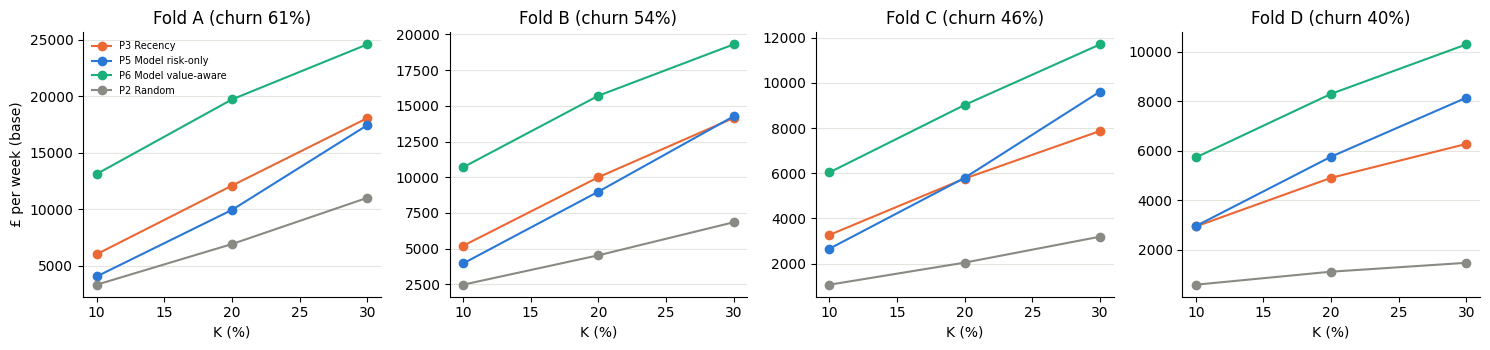

In [6]:
# Margin vs K per fold (base scenario)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=False)
cols = {"P3 Recency": ORANGE, "P5 Model risk-only": BLUE, "P6 Model value-aware": GREEN, "P2 Random": GREY}
for ax, name in zip(axes, folds):
    for pol, c in cols.items():
        ys = [fold_table(name, k, BASE)[0].loc[pol, "margin_week"] for k in K_GRID]
        ax.plot([int(k * 100) for k in K_GRID], ys, marker="o", color=c, label=pol)
    ax.set_title(f"Fold {name} (churn {folds[name]['test'].churn.mean():.0%})"); ax.set_xlabel("K (%)")
axes[0].set_ylabel("£ per week (base)"); axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig("../report/figures/ch11_backtest_policy_vs_k.png", dpi=150, bbox_inches="tight"); plt.show()

## 11.3 Per-fold calibration and segment actions

Does the base-rate shift show up per fold, and do the segment actions from
notebook 10 (offer / no discount) hold when churn is high?

In [7]:
seg_rows = []
for name, f in folds.items():
    t = f["test"]; g = pd.Series(row_gain(t, *BASE), index=t.index)
    s = g.groupby(t.rfm_segment).mean().round(2); s.name = name
    seg_rows.append(s)
display(pd.DataFrame(seg_rows).T.rename_axis("segment (realized £ per contact, base)"))
display(pd.DataFrame({n: f["test"].groupby("rfm_segment").churn.mean() for n, f in folds.items()}).round(2).rename_axis("segment churn rate"))

,A,B,C,D
"segment (realized £ per contact, base)",,,,
At Risk,21.14,18.00,14.59,12.52
Can't Lose,6.13,2.16,3.80,-1.62
Champions,-2.36,-5.21,-4.99,-6.58
Hibernating,19.47,16.89,13.31,11.86
Loyal,4.99,-2.45,-0.17,-2.80
Potential,16.23,11.60,10.58,6.49


,A,B,C,D
segment churn rate,,,,
At Risk,0.69,0.67,0.63,0.58
Can't Lose,0.42,0.38,0.39,0.30
Champions,0.31,0.24,0.25,0.21
Hibernating,0.86,0.84,0.76,0.72
Loyal,0.43,0.30,0.31,0.29
Potential,0.77,0.65,0.62,0.52


## 11.4 Blanket vs targeting by season

Blanket total per week and per contact, to show when untargeted discounts
destroy margin (Deep scenario).

In [8]:
rows = []
for sname, (d, e) in SCENARIOS.items():
    for name in folds:
        tab, _ = fold_table(name, 0.20, (d, e, M, R, C))
        rows.append(dict(scenario=sname, fold=name, blanket_week=tab.loc["P1 Blanket", "margin_week"],
                         blanket_per_contact=tab.loc["P1 Blanket", "margin_per_contact"],
                         P6_week=tab.loc["P6 Model value-aware", "margin_week"],
                         P6_per_contact=tab.loc["P6 Model value-aware", "margin_per_contact"]))
pd.DataFrame(rows).round(1)

,scenario,fold,blanket_week,blanket_per_contact,P6_week,P6_per_contact
0,Light,A,33906.1,10.8,17244.5,27.4
1,Light,B,22820.2,8.3,13103.9,23.8
2,Light,C,13703.7,6.0,8315.8,18.2
3,Light,D,9658.1,4.0,7820.5,16.1
4,Base,A,36679.6,11.7,19721.3,31.3
5,Base,B,22326.7,8.1,15705.2,28.5
6,Base,C,10719.7,4.7,9022.3,19.7
7,Base,D,4419.9,1.8,8300.1,17.1
8,Deep,A,9520.3,3.0,11478.4,18.2
9,Deep,B,-3351.5,-1.2,10326.9,18.7


## 11.5 Break-even gross margin by fold

Gross margin at which each policy's net margin is zero (K=20%, base discount/response).
The dataset has no margin data, so this shows how safe each policy is to the
margin assumption. Lower is safer.

In [9]:
rows = []
for name in folds:
    f = folds[name]
    t, masks, _ = masks_for(f["test"], f["train"], 0.20, BASE)
    rows.append({"fold": name, **{pol: margin_breakdown(t, mk, BASE)["break_even_margin_rate"] for pol, mk in masks.items()}})
display(pd.DataFrame(rows).set_index("fold").round(3))
f = folds["D"]; t, masks, _ = masks_for(f["test"], f["train"], 0.20, BASE)
display(pd.DataFrame({p: margin_breakdown(t, mk, BASE) for p, mk in masks.items()}).T.round(2).rename_axis("fold D decomposition (£/week)"))

,P1 Blanket,P2 Random,P3 Recency,P4b RFM segments (train-chosen),P5 Model risk-only,P6 Model value-aware
fold,,,,,,
A,0.213,0.218,0.160,0.147,0.130,0.134
B,0.249,0.246,0.161,0.158,0.134,0.149
C,0.300,0.303,0.198,0.241,0.163,0.188
D,0.354,0.344,0.221,0.257,0.173,0.210


,contacts_week,revenue_preserved_week,gross_margin_week,discount_on_responders_week,discount_wasted_on_buyers_week,contact_cost_week,net_margin_week,break_even_margin_rate
fold D decomposition (£/week),,,,,,,,
P1 Blanket,2425.2,96653.64,38661.46,-9665.36,-23363.63,-1212.6,4419.86,0.35
P2 Random,485.0,19929.97,7971.99,-1993.00,-4612.84,-242.5,1123.65,0.34
P3 Recency,485.0,27497.71,10999.09,-2749.77,-3096.01,-242.5,4910.80,0.22
P4b RFM segments (train-chosen),1422.0,68360.06,27344.02,-6836.01,-10038.26,-711.0,9758.76,0.26
P5 Model risk-only,485.0,25345.05,10138.02,-2534.50,-1595.81,-242.5,5765.20,0.17
P6 Model value-aware,485.0,43635.11,17454.04,-4363.51,-4547.95,-242.5,8300.09,0.21
